In [13]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


In [3]:
df = pd.read_csv("final.csv")
print(df.columns.tolist())

['Weight', 'Height']


In [4]:
df= df.drop_duplicates()
df= df.fillna(df.mean(numeric_only=True))

In [5]:
print(df)

        Weight      Height
0    67.062924  176.086355
1    68.804094  178.388669
2    60.930863  170.284496
3    59.733843  168.691992
4    65.431230  173.763679
..         ...         ...
495  59.976983  169.679741
496  66.423814  174.625574
497  53.604698  161.919208
498  50.433644  160.794875
499  60.224392  169.689709

[500 rows x 2 columns]


In [7]:
x= df[['Weight', 'Height']]


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [9]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.5, min_samples=5)

labels = dbscan.fit_predict(X_scaled)

print("Cluster labels:")
print(labels)

Cluster labels:
[0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 1 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0 0 0 1
 0 1 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 1 1 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0
 1 0 0 0 0 0 1 0 1 0 0 0 1 1 0 1 1 1 0 1 0 0 0 0 0 0 1 1 0 1 0 0 0 0 0 1 1
 0 1 1 0 1 0 0 0 0 0 1 0 0 1 0 0 0 0 1 0 1 0 1 1 1 0 0 0 0 0 0 0 0 0 1 0 0
 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 1 0 1 1 1 0 0 0 0 0
 1 0 0 0 1 0 0 1 0 0 1 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 0 0
 0 1 0 0 1 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 0 1 1 0 1
 0 0 0 0 1 0 0 0 0 1 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 1
 1 1 0 0 0 1 0 1 0 0 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 0 0 0 0 0 0 1
 0 0 0 1 0 0 0 1 1 0 1 1 0 1 1 0 0 0 0 1 1 1 1 0 1 0 0 0 1 0 0 0 0 0 0 0 1
 0 1 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0
 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 1 0 1 0
 0 0 1 0 

In [10]:
df["Cluster"] = labels

print(df.head())

      Weight      Height  Cluster
0  67.062924  176.086355        0
1  68.804094  178.388669        0
2  60.930863  170.284496        0
3  59.733843  168.691992        0
4  65.431230  173.763679        0


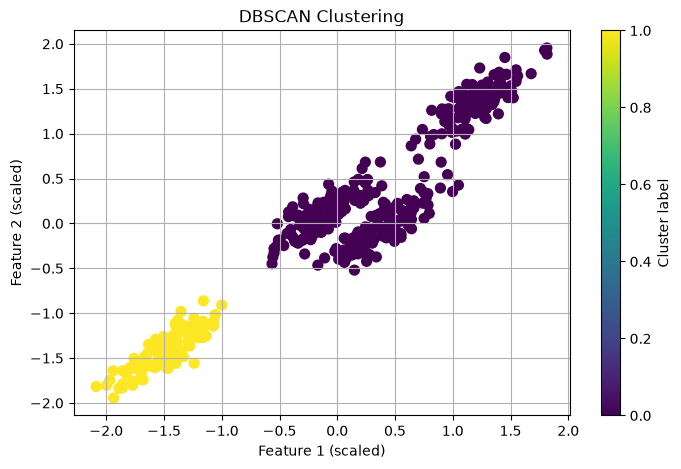

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis",
    s=50
)

plt.xlabel("Feature 1 (scaled)")
plt.ylabel("Feature 2 (scaled)")
plt.title("DBSCAN Clustering")
plt.colorbar(label="Cluster label")
plt.grid(True)
plt.show()